In [2]:
import torch

In [2]:
# We always start with a dataset to train on. Let's download the tiny shakespeare dataset
# !wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt

--2026-04-19 18:11:53--  https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.111.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1115394 (1.1M) [text/plain]
Saving to: ‘input.txt’

input.txt           100%[===================>]   1.06M  1.52MB/s    in 0.7s    

2026-04-19 18:11:54 (1.52 MB/s) - ‘input.txt’ saved [1115394/1115394]



In [3]:
with open("input.txt", 'r', encoding='utf-8') as f:
    text = f.read()

In [4]:
chars = sorted(list(set(text)))
vocab_size = len(chars)
print(''.join(chars))
print(vocab_size)


 !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz
65


In [5]:
# create a mapping from characters to integers
stoi = { ch:i for i,ch in enumerate(chars) }
itos = { i:ch for i,ch in enumerate(chars) }
encode = lambda s: [stoi[c] for c in s] # encoder: take a string, output a list of integers
decode = lambda l: ''.join([itos[i] for i in l]) # decoder: take a list of integers, output a string

print(encode("hii there"))
print(decode(encode("hii there")))

[46, 47, 47, 1, 58, 46, 43, 56, 43]
hii there


In [6]:
data = torch.tensor(encode(text), dtype=torch.long)
print(data.shape, data.dtype)
data[:100]

torch.Size([1115394]) torch.int64


tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56, 43,  1, 61, 43,  1, 54, 56, 53, 41, 43, 43, 42,  1, 39, 52, 63,
         1, 44, 59, 56, 58, 46, 43, 56,  6,  1, 46, 43, 39, 56,  1, 51, 43,  1,
        57, 54, 43, 39, 49,  8,  0,  0, 13, 50, 50, 10,  0, 31, 54, 43, 39, 49,
         6,  1, 57, 54, 43, 39, 49,  8,  0,  0, 18, 47, 56, 57, 58,  1, 15, 47,
        58, 47, 64, 43, 52, 10,  0, 37, 53, 59])

In [7]:
n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]

In [13]:
torch.manual_seed(1337)
block_size = 8 # context_length
batch_size = 4

def get_batch(split):
    data = train_data if split=="train" else val_data
    x = torch.zeros((batch_size, block_size), dtype=torch.long)
    y = torch.zeros((batch_size, block_size), dtype=torch.long)
    for i in range(batch_size):
        idx = torch.randint((len(data) - block_size), (1,))
        x[i] = data[idx:idx + block_size]
        y[i] = data[idx + 1:idx + block_size + 1]

    return x, y
        
xb, yb = get_batch('train')
print('inputs:')
print(xb.shape)
print(xb)
print('targets:')
print(yb.shape)
print(yb)

print('----')

for b in range(batch_size):
    for t in range(block_size):
        context = xb[b,: t + 1]
        target = yb[b, t]
        print(f'When input is {context.tolist()}, output should be {target}')

inputs:
torch.Size([4, 8])
tensor([[24, 43, 58,  5, 57,  1, 46, 43],
        [44, 53, 56,  1, 58, 46, 39, 58],
        [52, 58,  1, 58, 46, 39, 58,  1],
        [25, 17, 27, 10,  0, 21,  1, 54]])
targets:
torch.Size([4, 8])
tensor([[43, 58,  5, 57,  1, 46, 43, 39],
        [53, 56,  1, 58, 46, 39, 58,  1],
        [58,  1, 58, 46, 39, 58,  1, 46],
        [17, 27, 10,  0, 21,  1, 54, 39]])
----
When input is [24], output should be 43
When input is [24, 43], output should be 58
When input is [24, 43, 58], output should be 5
When input is [24, 43, 58, 5], output should be 57
When input is [24, 43, 58, 5, 57], output should be 1
When input is [24, 43, 58, 5, 57, 1], output should be 46
When input is [24, 43, 58, 5, 57, 1, 46], output should be 43
When input is [24, 43, 58, 5, 57, 1, 46, 43], output should be 39
When input is [44], output should be 53
When input is [44, 53], output should be 56
When input is [44, 53, 56], output should be 1
When input is [44, 53, 56, 1], output should be 5

In [14]:
import torch.nn as nn
import torch.nn.functional as F


class BigramLanguageModel(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embs = nn.Embedding(vocab_size, vocab_size)

    def forward(self, x, target=None):
        # shape of x wil be (batch_size, block_size)
        logits = self.embs(x)  # (batch_size, block_size, vocab_size)

        if target is None:
            loss = None
        else:
            # but our targets shape will be batch_size by block_size
            B, T, C = logits.shape
            logits = logits.view(B * T, C)
            target = target.view(B * T)
            loss = F.cross_entropy(logits, target)
        return logits, loss
    
    def generate(self, max_tokens):
        context = torch.zeros((1, 1), dtype=torch.long)
        for _ in range(max_tokens):
            logits , loss = self.forward(context)
            logits = logits[:, -1, :] # focus only on the last time step
            probs = F.softmax(logits, dim=-1)
            id_next = torch.multinomial(probs, num_samples=1)
            context = torch.cat((context, id_next), dim=1)

        return context

m = BigramLanguageModel(vocab_size)
print(decode(m.generate(200)[0].tolist())) # garbage output since we haven't trained the model yet!


lfJeukRuaRJKXAYtXzfJ:HEPiu--sDioi;ILCo3pHNTmDwJsfheKRxZCFs
lZJ XQc?:s:HEzEnXalEPklcPU cL'DpdLCafBheHd:.?nA!LgjgL&jcM-sZW!HFsWt'rv.x;z&hPyd'XHOxnAcj.erRjcLxxVFSrOpW.oeGJ Ai$yi&!mRfeopx,f.e..iBgxVrl-VTh


In [15]:
optimizer = torch.optim.AdamW(m.parameters(), lr=1e-3)
batch_size = 32
for steps in range(10000):
    xb, yb = get_batch('train')
    logits, loss = m(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
print(loss.item())

2.574044942855835


In [16]:
print(decode(m.generate(200)[0].tolist()))
# after training, the generated text should look less random




ARERI ISOLBUS:
QUK: ast, plt t wadyotl
I bel qunganonoth he m he de avellis k'l, tond soran:

WI he toust are bott oe n t s d je hid t his IAces I my ig t
Ril'swoll e pupat inould candenothiqu heame


## Self Attention

In [20]:
torch.manual_seed(1337)
B,T,C = 1,8,2 # batch, time, channels
x = torch.randn(B,T,C)
x.shape
# lets start with simplest form of attention, where  we want x[b, t] = mean(x[b, :t+1])

torch.Size([1, 8, 2])

In [21]:
# version 1 naive way
xbow = torch.zeros_like(x)
for b in range(B):
    for t in range(T):
        xbow[b, t] = torch.mean(x[b, :t+1], dim=0)
xbow[0]
        

tensor([[ 0.1808, -0.0700],
        [-0.0894, -0.4926],
        [ 0.1490, -0.3199],
        [ 0.3504, -0.2238],
        [ 0.3525,  0.0545],
        [ 0.0688, -0.0396],
        [ 0.0927, -0.0682],
        [-0.0341,  0.1332]])

In [22]:
# version two using matrix mul
wei = torch.tril(torch.ones(T, T))
wei = wei / torch.sum(wei, dim=1, keepdim=True)
xbow2 = (wei @ x)
torch.allclose(xbow, xbow2)

True

In [23]:
(wei@ x[0] - xbow[0]) < 1e-7

tensor([[True, True],
        [True, True],
        [True, True],
        [True, True],
        [True, True],
        [True, True],
        [True, True],
        [True, True]])

In [24]:
# version 3 using softmax
tril = torch.tril(torch.ones(T, T))
wei = torch.zeros_like(tril)
wei = torch.masked_fill(wei, tril == 0, float("-inf"))
wei = wei.softmax(dim=1)
xbow3 = wei @ x
wei

tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.5000, 0.5000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3333, 0.3333, 0.3333, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2500, 0.2500, 0.2500, 0.2500, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2000, 0.2000, 0.2000, 0.2000, 0.2000, 0.0000, 0.0000, 0.0000],
        [0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.1667, 0.0000, 0.0000],
        [0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.1429, 0.0000],
        [0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250, 0.1250]])

In [25]:
torch.allclose(xbow3, xbow)

True

In [26]:
x

tensor([[[ 0.1808, -0.0700],
         [-0.3596, -0.9152],
         [ 0.6258,  0.0255],
         [ 0.9545,  0.0643],
         [ 0.3612,  1.1679],
         [-1.3499, -0.5102],
         [ 0.2360, -0.2398],
         [-0.9211,  1.5433]]])

In [ ]:
# using self attention
import math

b, t, c = x.shape

head_size = 4
key = nn.Linear(c,head_size , bias=False)
query = nn.Linear(c,head_size , bias=False)
value = nn.Linear(c,head_size , bias=False)

# get the q, k, v, vectors for each token
q = query(x)
k = key(x)
q.shape # should be b, t, head_size: (1, 8, 4)

# this represets something that x[0] queries for with other tokens
# q[0,0,:]
# this represets something that x[0] can provide for with other tokens
# k[0,0,:]

attn_score = ((q @ torch.transpose(k, -2, -1)) / math.sqrt(head_size))
masked_attn = attn_score.masked_fill(torch.tril(torch.ones(T, T)) == 0, float("-inf"))
attn_score = attn_score.softmax(dim=-1)

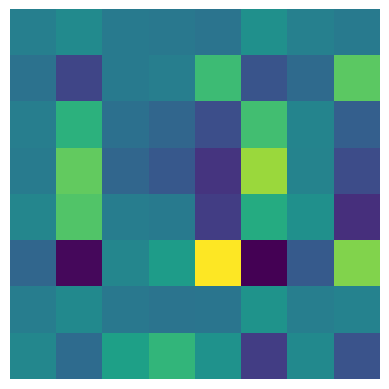

In [28]:
import matplotlib.pyplot as plt
plt.imshow(attn_score[0].detach().numpy());
plt.axis(False);

In [31]:
# now lets code the complete decoder only transoformer
import torch
import torch.nn as nn
from torch.nn import functional as F

# hyperparameters
batch_size = 16  # how many independent sequences will we process in parallel?
block_size = 32  # what is the maximum context length for predictions?
max_iters = 200
eval_interval = 20
learning_rate = 1e-3
device = "cuda" if torch.cuda.is_available() else "cpu"
eval_iters = 200
n_embd = 64
n_head = 4
n_layer = 2
dropout = 0.1
# ------------

torch.manual_seed(1337)

# wget https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt
with open("input.txt", "r", encoding="utf-8") as f:
    text = f.read()

# here are all the unique characters that occur in this text
chars = sorted(list(set(text)))
vocab_size = len(chars)
# create a mapping from characters to integers
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}
encode = lambda s: [
    stoi[c] for c in s
]  # encoder: take a string, output a list of integers
decode = lambda l: "".join(
    [itos[i] for i in l]
)  # decoder: take a list of integers, output a string

# Train and test splits
data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))  # first 90% will be train, rest val
train_data = data[:n]
val_data = data[n:]


# data loading
def get_batch(split):
    # generate a small batch of data of inputs x and targets y
    data = train_data if split == "train" else val_data
    ix = torch.randint(len(data) - block_size, (batch_size,))
    x = torch.stack([data[i : i + block_size] for i in ix])
    y = torch.stack([data[i + 1 : i + block_size + 1] for i in ix])
    x, y = x.to(device), y.to(device)
    return x, y


@torch.no_grad()
def estimate_loss():
    out = {}
    model.eval()
    for split in ["train", "val"]:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            X, Y = get_batch(split)
            logits, loss = model(X, Y)
            losses[k] = loss.item()
        out[split] = losses.mean()
    model.train()
    return out


class Head(nn.Module):
    def __init__(self, head_size):
        super().__init__()
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))
        self.dropout = nn.Dropout(p=0.2)

    def forward(self, x):
        # x will have shape -> batch, blocksize, n_embed
        B, T, C = x.shape
        q = self.query(x)
        k = self.key(x)
        v = self.value(x)

        wei = q @ k.transpose(-2, -1) * C**-0.5
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float("-inf"))
        wei = wei.softmax(dim=-1)

        # v.shape = b, t, h
        # wei.shape = b, t, t
        out = wei @ v  # shape -> b, t, h

        return out  # this is the out value of a single head


class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList(
            [Head(head_size=head_size) for _ in range(num_heads)]
        )
        self.proj = nn.Linear(n_embd, n_embd)
        self.dropout = nn.Dropout()

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        out = self.dropout(self.proj(out))
        return out


class FeedForward(nn.Module):
    def __init__(self, n_embd):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    def __init__(self, n_embd, n_head):
        super().__init__()
        # n_ head should be integer multiple of nembed
        head_size = n_embd // n_head

        self.sa = MultiHeadAttention(n_head, head_size)
        self.ff = FeedForward(n_embd)
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        # x = self.ln1(x + self.sa(x)) # this is post layer norm, hard to converge
        # warmup of lr needed
        # standard today is pre-layer norm
        x = x + self.sa(self.ln1(x))
        x = x + self.ff(self.ln2(x))
        return x


class BigramLanguageModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_embedding_table = nn.Embedding(vocab_size, n_embd)
        self.pos_embedding_table = nn.Embedding(block_size, n_embd)
        # self.blocks = nn.Sequential(*[Block(n_embd, n_head) for _ in range(n_layer)])
        # self.blocks = nn.Sequential(*[Block(n_embd, n_head=n_head) for _ in range(n_layer)])
        self.blocks = nn.ModuleList([Block(n_embd, n_head) for _ in range(n_layer)])
        self.lnf = nn.LayerNorm(n_embd)
        self.lmhead = nn.Linear(n_embd, vocab_size)

    def forward(self, ix, targets=None):
        B, T = ix.shape
        tok_embs = self.token_embedding_table(ix)
        pos_embs = self.pos_embedding_table(torch.arange(T, device=device))
        x = tok_embs + pos_embs
        for block in self.blocks:
            x = block(x)
        x = self.lnf(x)
        logits = self.lmhead(x)

        if targets is None:
            loss = None
        else:
            # target.shape => B, T
            # logits.shape => B, T, vocab_size
            B, T, C = logits.shape
            logits = logits.view(B * T, C)
            targets = targets.view(B * T)
            # in cross entropy logits are of shape(n_pred, n_classes)
            # targets should be of shape(n_pred)
            loss = F.cross_entropy(logits, targets)
        return logits, loss

    def generate(self, idx, max_tokens=1000):
        for _ in range(max_tokens):
            # get just the previous blocksize indices
            idx_cond = idx[:, -block_size:]

            logits, loss = self(idx_cond)

            # but we only get the prediction for the final timestep during generation

            logits = logits[:, -1, :].softmax(dim=-1)  # shape => b, t, vocab_size
            idx_next = torch.multinomial(logits, num_samples=1)

            idx = torch.cat((idx, idx_next), dim=1)
        return idx


model = BigramLanguageModel()
m = model.to(device)
# print the number of parameters in the model
print(sum(p.numel() for p in m.parameters()) / 1e6, "M parameters")


0.110145 M parameters


In [35]:
# create a PyTorch optimizer
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
for iter in range(max_iters):

    # every once in a while evaluate the loss on train and val sets
    if iter % eval_interval == 0 or iter == max_iters - 1:
        losses = estimate_loss()
        print(
            f"step {iter}: train loss {losses['train']:.4f}, val loss {losses['val']:.4f}"
        )

    # sample a batch of data
    xb, yb = get_batch("train")

    # evaluate the loss
    logits, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

step 0: train loss 2.3605, val loss 2.3712
step 20: train loss 2.3694, val loss 2.3764
step 40: train loss 2.3556, val loss 2.3577
step 60: train loss 2.3592, val loss 2.3452
step 80: train loss 2.3404, val loss 2.3460
step 100: train loss 2.3414, val loss 2.3406
step 120: train loss 2.3329, val loss 2.3486
step 140: train loss 2.3210, val loss 2.3439
step 160: train loss 2.3181, val loss 2.3309
step 180: train loss 2.3125, val loss 2.3201
step 199: train loss 2.3073, val loss 2.3147


In [36]:
# geenrate
context = torch.zeros((1, 1), dtype=torch.long, device=device)
# m.generate(context, 2000)
print(decode(m.generate(context, 2000)[0].tolist()))


I ove thell it ceearun kay low ale wewes cer omacce thern:ereThals in' the gryousamses nons nor gevellp,
And
AUns BoThy we
Wcrerdow th moue civer;
BEKInsed to avend.
;

IO would,
F hose BINury.
A:
Wexer song! athy themhid lld bondis.
PA BA:
Has ThaGfor' beinds:
A oouprir thive Rhemakeas;
I It rrie thof pois, miy
Anghbrrend he nom thag kopes oy hirit e buend sfitin nist 'bos spill beli:
Athof onhpeuar hicing ull it ar,
I is Imeare whis hees,
Hm- tha noum hiry ste cery I ariofuwt handers thenver.

GLO:
Fick hed iy
Thol is th, rom goos; my ak, ityow iinge,
And wiNre ice thepr ge hy an ceravearsot sinds, on aresw silveave
Te heg, foorasems, t eismucom yoof hary highe low, ad.

Havetr:
A
Vror thy reit lives?;
I Pey ithed hond fou lem heacrace
Mprrmes tarad is hels aisw bll;
Whin e his meds IZth Imelsisd ipry,'s: whe went wil mior
This et whees yeacar no te, ise sem dealls whans lond:
Incooke wring tostroose e brded besit tow be wigulaiy:
Bor wome an fundeve hempse'd hend st thed aand
I e-p